In [2]:
!pip install sympy matplotlib numpy




   ---------------------------------------- 0.0/6.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/6.3 MB ? eta -:--:--
   ---- ----------------------------------- 0.8/6.3 MB 1.7 MB/s eta 0:00:04
   ------ --------------------------------- 1.0/6.3 MB 1.6 MB/s eta 0:00:04
   --------- ------------------------------ 1.6/6.3 MB 1.7 MB/s eta 0:00:03
   ----------- ---------------------------- 1.8/6.3 MB 1.7 MB/s eta 0:00:03
   ------------- -------------------------- 2.1/6.3 MB 1.7 MB/s eta 0:00:03
   ---------------- ----------------------- 2.6/6.3 MB 1.7 MB/s eta 0:00:03
   ------------------ --------------------- 2.9/6.3 MB 1.7 MB/s eta 0:00:03
   ------------------- -------------------- 3.1/6.3 MB 1.7 MB/s eta 0:00:02
   ----------------------- ---------------- 3.7/6.3 MB 1.7 MB/s eta 0:00:02
   ------------------------ --------------- 3.9/6.3 MB 1.7 MB/s eta 0:00:02
   -------------------------- ---


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# Make plots look clean and crisp
%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['font.size'] = 11


In [ ]:


# Features: [Size in 1000 sq ft, Number of Rooms]
X = np.array([
    [1.5, 2],
    [2.0, 3],
    [2.5, 3],
    [3.0, 4],
    [3.5, 5]
])

# Target: True House Prices (in $100k)
y = np.array([2.5, 3.2, 3.8, 4.6, 5.3])

print("--- OUR ML DATASET ---")
print("Features X (Size, Rooms):\n", X)
print("\nTarget y (Prices in $100k):\n", y)


--- OUR ML DATASET ---
Features X (Size, Rooms):
 [[1.5 2. ]
 [2.  3. ]
 [2.5 3. ]
 [3.  4. ]
 [3.5 5. ]]

Target y (Prices in $100k):
 [2.5 3.2 3.8 4.6 5.3]


In [5]:
print("--- 1. VECTORS AS DATA POINTS & WEIGHTS ---")
# Intuition: Every row in our dataset is a feature vector.
# Let's define a weight vector that maps feature values to a price prediction.
v_data = X[0]      # Feature vector for the first house: [1.5, 2]
w_weights = np.array([1.2, 0.4]) # Weights: $120k per 1k sq ft, $40k per room

print(f"House 1 Vector: {v_data}")
print(f"Weight Vector: {w_weights}")

print("\n--- 2. DOT PRODUCT AS PREDICTION ---")
# Intuition: The dot product multiplies features by their weights and sums them up.
# This gives us our predicted house price!
predicted_price = np.dot(v_data, w_weights)
print(f"Dot Product (Predicted Price): ${predicted_price:.2f}k")

print("\n--- 3. MATRICES AS BATCH PROCESSING ---")
# Intuition: Instead of computing the dot product for each house one by one, 
# multiplying the Matrix X by the Weight Vector w calculates predictions for ALL houses instantly.
all_predictions = X.dot(w_weights)
print(f"Matrix-Vector Product (All Predictions):\n{all_predictions}")

print("\n--- 4. EIGENVALUES & EIGENVECTORS (Data Spread) ---")
# Intuition: In ML, we use eigenvalues/eigenvectors on a dataset's covariance matrix (PCA).
# The eigenvector shows the direction of maximum variance (spread) of our data.
# The eigenvalue tells us how stretched out the data is along that direction.
covariance_matrix = np.cov(X.T)
eigenvalues, eigenvectors = np.linalg.eig(covariance_matrix)
print("Directions of data spread (Eigenvectors):\n", eigenvectors)
print("Amount of data spread (Eigenvalues):", eigenvalues)


--- 1. VECTORS AS DATA POINTS & WEIGHTS ---
House 1 Vector: [1.5 2. ]
Weight Vector: [1.2 0.4]

--- 2. DOT PRODUCT AS PREDICTION ---
Dot Product (Predicted Price): $2.60k

--- 3. MATRICES AS BATCH PROCESSING ---
Matrix-Vector Product (All Predictions):
[2.6 3.6 4.2 5.2 6.2]

--- 4. EIGENVALUES & EIGENVECTORS (Data Spread) ---
Directions of data spread (Eigenvectors):
 [[-0.82458234+0.j -0.56574196+0.j]
 [ 0.56574196+0.j -0.82458234+0.j]]
Amount of data spread (Eigenvalues): [0.02466673+0.j 1.90033327+0.j]


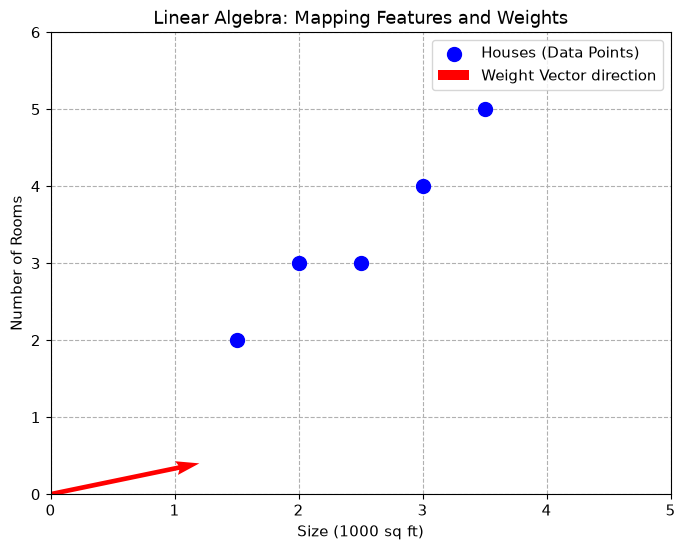

In [6]:
fig, ax = plt.subplots()

# Plot our dataset points
ax.scatter(X[:, 0], X[:, 1], color='blue', s=100, label='Houses (Data Points)', zorder=3)

# Plot the weight vector pointing in the direction of high value
ax.quiver(0, 0, w_weights[0], w_weights[1], angles='xy', scale_units='xy', scale=1, 
          color='red', label='Weight Vector direction', zorder=2)

ax.set_xlim(0, 5)
ax.set_ylim(0, 6)
ax.set_xlabel('Size (1000 sq ft)')
ax.set_ylabel('Number of Rooms')
ax.grid(True, linestyle='--')
ax.legend()
ax.set_title("Linear Algebra: Mapping Features and Weights")
plt.show()


In [7]:
print("--- 1. DERIVATIVES AS ERROR MARGINS ---")
# Intuition: If our weight (w) shifts, how much does our Error change? 
# The derivative gives us the exact rate of change of the error.
w = sp.Symbol('w')
# Mean Squared Error formula for a simple single point: Error = (Predicted - True)^2
# Let's say Prediction = w * 1.5, True = 2.5
error_func = (w * 1.5 - 2.5)**2
dError_dw = sp.diff(error_func, w)

print(f"Error Function: {error_func}")
print(f"Derivative (Slope of Error): {dError_dw}")
print(f"Slope at current weight w=1.2: {dError_dw.subs(w, 1.2):.2f}")
print("Interpretation: A negative slope means increasing the weight will decrease the error.")

print("\n--- 2. GRADIENTS AS THE STEERING WHEEL ---")
# Intuition: With multiple weights, the Gradient vector holds all partial derivatives.
# Moving opposite to the gradient vector (-gradient) lowers our model's error.
w1, w2 = sp.Symbol('w1'), sp.Symbol('w2')
# Error using two features: Size(1.5) and Rooms(2)
complex_error = (w1 * 1.5 + w2 * 2 - 2.5)**2
grad_w1 = sp.diff(complex_error, w1)
grad_w2 = sp.diff(complex_error, w2)

print(f"Gradient Vector: [dError/dw1, dError/dw2] = [{grad_w1}, {grad_w2}]")


--- 1. DERIVATIVES AS ERROR MARGINS ---
Error Function: (1.5*w - 2.5)**2
Derivative (Slope of Error): 4.5*w - 7.5
Slope at current weight w=1.2: -2.10
Interpretation: A negative slope means increasing the weight will decrease the error.

--- 2. GRADIENTS AS THE STEERING WHEEL ---
Gradient Vector: [dError/dw1, dError/dw2] = [4.5*w1 + 6.0*w2 - 7.5, 6.0*w1 + 8*w2 - 10.0]


In [9]:
print("--- THE CHAIN RULE IN ACTION ---")

# 1. Define independent SymPy symbols
w1 = sp.Symbol('w1')
pred = sp.Symbol('pred') # Declared as a pure symbol now

x1 = 1.5     # House Size
y_true = 2.5

# 2. Define equations using those pure symbols
L = (pred - y_true)**2
z = w1 * x1

# 3. Backward Pass via Chain Rule: dL/dw1 = dL/dpred * dpred/dz * dz/dw1
dL_dpred = sp.diff(L, pred)                  # Derivative of Loss wrt Prediction
dpred_dz = 1                                 # Derivative of Prediction wrt z (linear mapping)
dz_dw1 = sp.diff(z, w1)                      # Derivative of z wrt weight

# Multiply them together according to Chain Rule
dL_dw1_formula = dL_dpred * dpred_dz * dz_dw1

# 4. Substitute the actual expression of pred (which equals z) back into the formula
dL_dw1 = dL_dw1_formula.subs(pred, z)

print(f"1. How Loss changes with Prediction (dL/dpred): {dL_dpred}")
print(f"2. How Prediction changes with internal output (dpred/dz): {dpred_dz}")
print(f"3. How internal output changes with weight (dz/dw1): {dz_dw1}")
print(f"\nCalculated Chain Rule Gradient (dL/dw1): {dL_dw1}")

# Evaluate at current weight w1 = 1.2
current_grad = dL_dw1.subs(w1, 1.2)
print(f"Numerical Gradient at w1=1.2: {current_grad:.2f}")


--- THE CHAIN RULE IN ACTION ---
1. How Loss changes with Prediction (dL/dpred): 2*pred - 5.0
2. How Prediction changes with internal output (dpred/dz): 1
3. How internal output changes with weight (dz/dw1): 1.50000000000000

Calculated Chain Rule Gradient (dL/dw1): 4.5*w1 - 7.5
Numerical Gradient at w1=1.2: -2.10


In [10]:
print("--- PUTTING IT ALL TOGETHER: THE TRAINING LOOP ---")

# Initial setup
w1_current = 1.2     # Starting weight guess
learning_rate = 0.1  # How big of a step to take down the slope
epochs = 5           # Number of training iterations

x1 = 1.5             # House Size from our dataset
y_true = 2.5         # True Price from our dataset

print(f"Starting Training: Initial Weight = {w1_current}, Target Price = {y_true}\n")

# We loop to let the calculus update our linear algebra weights
for epoch in range(1, epochs + 1):
    # 1. Forward Pass (Linear Algebra)
    y_pred = w1_current * x1
    
    # 2. Calculate Error/Loss
    loss = (y_pred - y_true)**2
    
    # 3. Calculate Gradient (Using the Calculus formula we just solved: 3.0*w1 - 7.5)
    # Derived from: 2 * (1.5*w1 - 2.5) * 1.5 = 4.5*w1 - 7.5
    gradient = 4.5 * w1_current - 7.5
    
    # 4. Update the Weight (Gradient Descent Step)
    # We subtract because we want to go DOWN the hill of error
    w1_current = w1_current - (learning_rate * gradient)
    
    # Print the progress
    print(f"Epoch {epoch}:")
    print(f"  Prediction: {y_pred:.2f} (Target: {y_true})")
    print(f"  Current Loss: {loss:.4f}")
    print(f"  Gradient (Slope): {gradient:.2f}")
    print(f"  Updated Weight for next step: {w1_current:.4f}\n")

print(f"Training Finished! Optimal Weight found: {w1_current:.4f}")
print(f"Final Prediction: {w1_current * x1:.2f} (Extremely close to {y_true}!)")


--- PUTTING IT ALL TOGETHER: THE TRAINING LOOP ---
Starting Training: Initial Weight = 1.2, Target Price = 2.5

Epoch 1:
  Prediction: 1.80 (Target: 2.5)
  Current Loss: 0.4900
  Gradient (Slope): -2.10
  Updated Weight for next step: 1.4100

Epoch 2:
  Prediction: 2.12 (Target: 2.5)
  Current Loss: 0.1482
  Gradient (Slope): -1.15
  Updated Weight for next step: 1.5255

Epoch 3:
  Prediction: 2.29 (Target: 2.5)
  Current Loss: 0.0448
  Gradient (Slope): -0.64
  Updated Weight for next step: 1.5890

Epoch 4:
  Prediction: 2.38 (Target: 2.5)
  Current Loss: 0.0136
  Gradient (Slope): -0.35
  Updated Weight for next step: 1.6240

Epoch 5:
  Prediction: 2.44 (Target: 2.5)
  Current Loss: 0.0041
  Gradient (Slope): -0.19
  Updated Weight for next step: 1.6432

Training Finished! Optimal Weight found: 1.6432
Final Prediction: 2.46 (Extremely close to 2.5!)


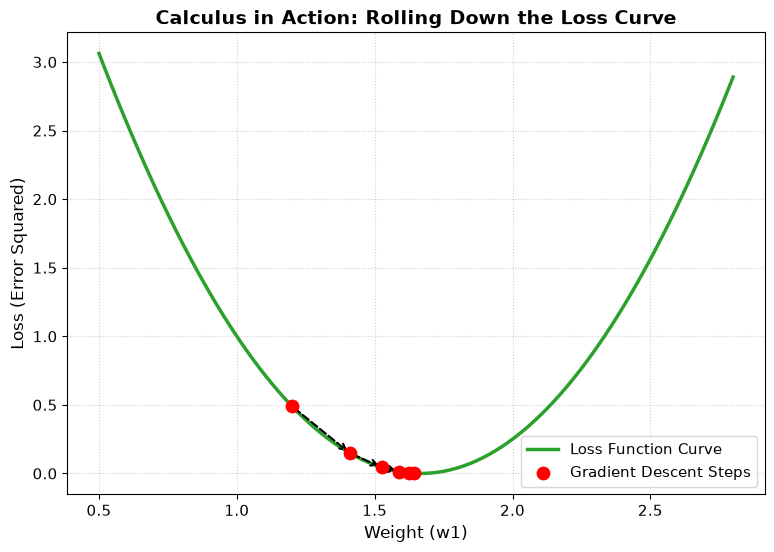

In [11]:
# Create a range of possible weights to plot the error curve
w_space = np.linspace(0.5, 2.8, 100)
loss_space = (w_space * 1.5 - 2.5)**2

# Track the actual weight steps taken during training
w_history = [1.2]
w_current = 1.2
for _ in range(5):
    gradient = 4.5 * w_current - 7.5
    w_current = w_current - (0.1 * gradient)
    w_history.append(w_current)

loss_history = [(w * 1.5 - 2.5)**2 for w in w_history]

# Plotting the visualization
plt.figure(figsize=(9, 6))
plt.plot(w_space, loss_space, color='#2ca02c', linewidth=2.5, label='Loss Function Curve')
plt.scatter(w_history, loss_history, color='red', s=80, zorder=5, label='Gradient Descent Steps')

# Draw arrows indicating the path taken
for i in range(len(w_history)-1):
    plt.annotate('', xy=(w_history[i+1], loss_history[i+1]), xytext=(w_history[i], loss_history[i]),
                 arrowprops=dict(arrowstyle="->", color='black', lw=1.5, ls='--'))

plt.title('Calculus in Action: Rolling Down the Loss Curve', fontsize=14, fontweight='bold')
plt.xlabel('Weight (w1)', fontsize=12)
plt.ylabel('Loss (Error Squared)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()
